In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

sns.set_theme(style="whitegrid")

housing = pd.read_csv("data/AmesHousing.csv", sep="\t")

print("Dataset dimensions:", housing.shape)
display(housing.head())

Dataset dimensions: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
numeric_features = housing.select_dtypes(include=np.number).columns.tolist()
categorical_features = housing.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of numeric features:", len(numeric_features))
print("Numeric features:")
print(numeric_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Categorical features:")
print(categorical_features)

Number of numeric features: 39
Numeric features:
['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold', 'SalePrice']

Number of categorical features: 43
Categorical features:
['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt

C:\Users\claud\AppData\Local\Temp\ipykernel_3872\361931520.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = housing.select_dtypes(


In [5]:
# Select numeric columns
numeric_data = housing.select_dtypes(include=np.number)

# Correlations with SalePrice
correlations = numeric_data.corr(numeric_only=True)["SalePrice"].drop(
    "SalePrice"
)

print("Features most positively correlated with SalePrice:")
display(correlations.sort_values(ascending=False).head(10))

print("Features most negatively correlated with SalePrice:")
display(correlations.sort_values().head(10))

Features most positively correlated with SalePrice:


Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Name: SalePrice, dtype: float64

Features most negatively correlated with SalePrice:


PID               -0.246521
Enclosed Porch    -0.128787
Kitchen AbvGr     -0.119814
Overall Cond      -0.101697
MS SubClass       -0.085092
Low Qual Fin SF   -0.037660
Bsmt Half Bath    -0.035835
Order             -0.031408
Yr Sold           -0.030569
Misc Val          -0.015691
Name: SalePrice, dtype: float64

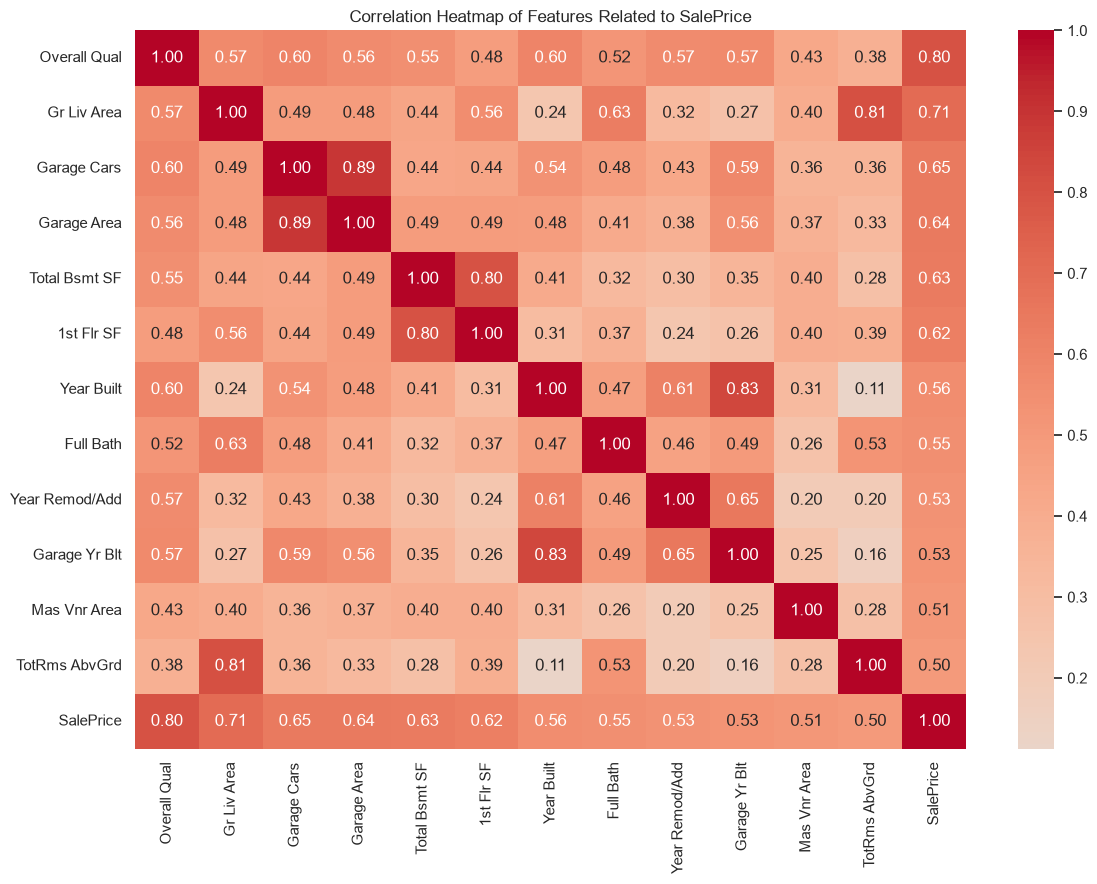

In [6]:
#heatmap
top_features = correlations.abs().sort_values(ascending=False).head(12).index
heatmap_data = housing[list(top_features) + ["SalePrice"]].corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Heatmap of Features Related to SalePrice")
plt.tight_layout()
plt.show()

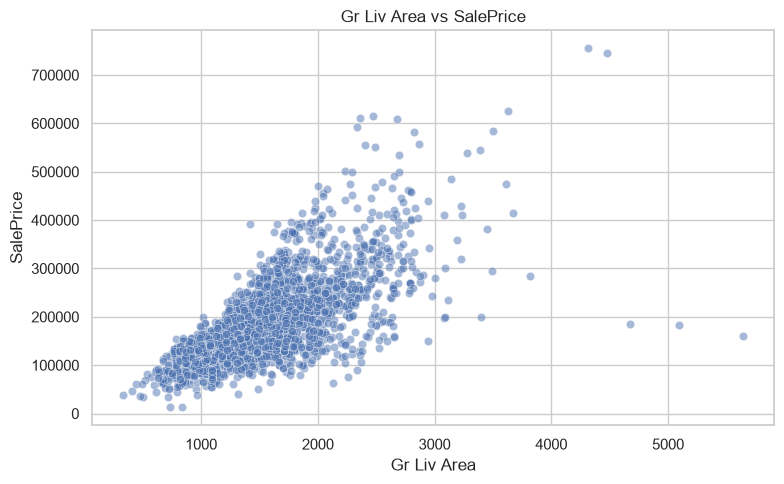

Correlation between Gr Liv Area and SalePrice: 0.707


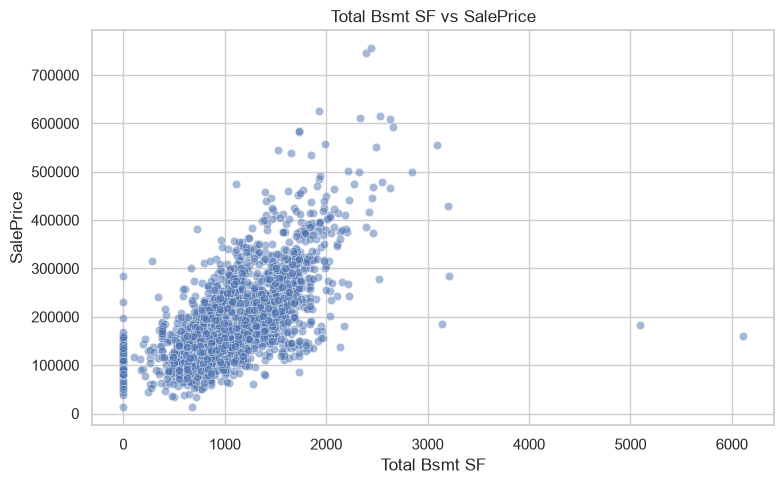

Correlation between Total Bsmt SF and SalePrice: 0.632


In [7]:
pairs = [
    ("Gr Liv Area", "SalePrice"),
    ("Total Bsmt SF", "SalePrice")
]

for x_col, y_col in pairs:
    if x_col in housing.columns and y_col in housing.columns:
        plot_data = housing[[x_col, y_col]].dropna()

        plt.figure(figsize=(8, 5))
        sns.scatterplot(data=plot_data, x=x_col, y=y_col, alpha=0.5)
        plt.title(f"{x_col} vs {y_col}")
        plt.tight_layout()
        plt.show()

        print(
            f"Correlation between {x_col} and {y_col}:",
            round(plot_data[x_col].corr(plot_data[y_col]), 3)
        )
    else:
        print(f"Missing column: {x_col} or {y_col}")

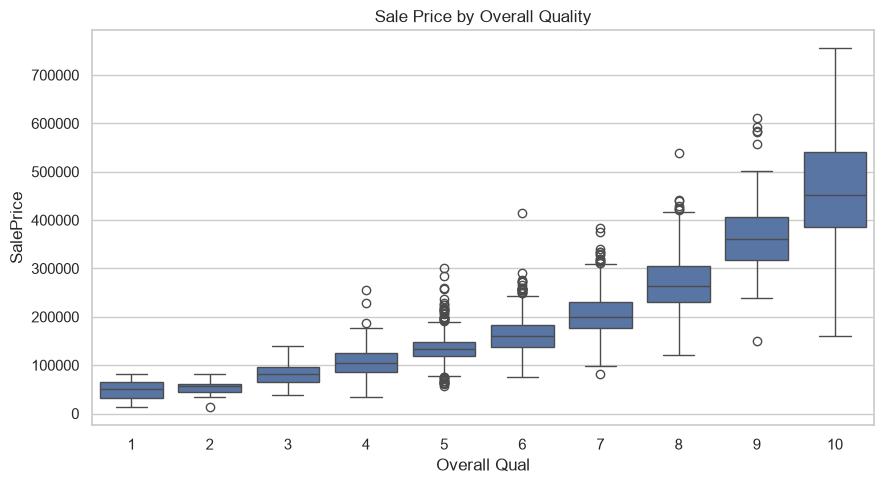

In [10]:
#Pret in functie de calitatea generala:
if "Overall Qual" in housing.columns:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=housing, x="Overall Qual", y="SalePrice")
    plt.title("Sale Price by Overall Quality")
    plt.tight_layout()
    plt.show()

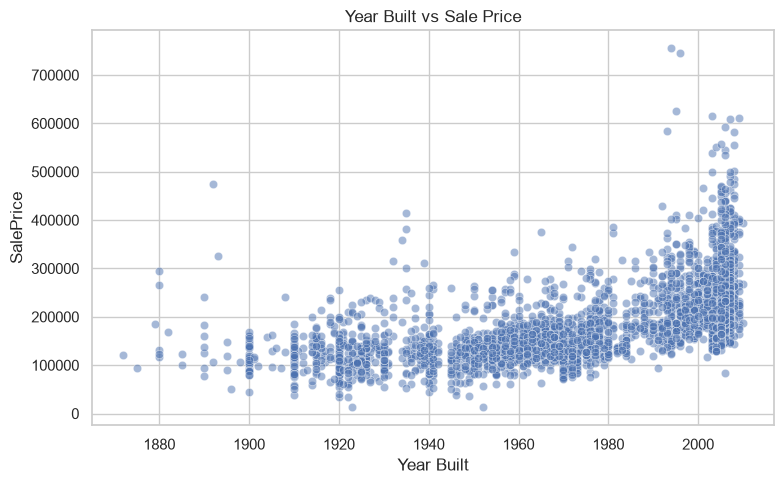

In [11]:
#relatia dintre anul constructiei si pret
if "Year Built" in housing.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=housing, x="Year Built", y="SalePrice", alpha=0.5)
    plt.title("Year Built vs Sale Price")
    plt.tight_layout()
    plt.show()

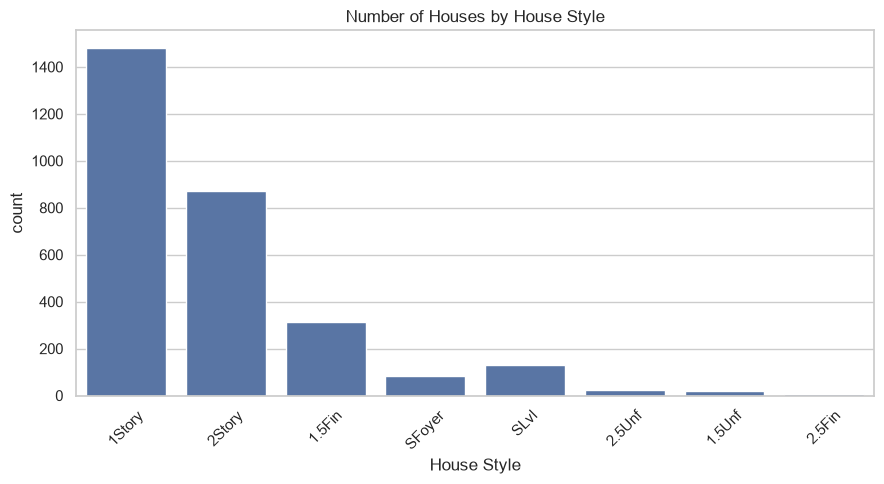

In [12]:
#count plot pentru tipul de locuinta
if "House Style" in housing.columns:
    plt.figure(figsize=(9, 5))
    sns.countplot(data=housing, x="House Style")
    plt.xticks(rotation=45)
    plt.title("Number of Houses by House Style")
    plt.tight_layout()
    plt.show()

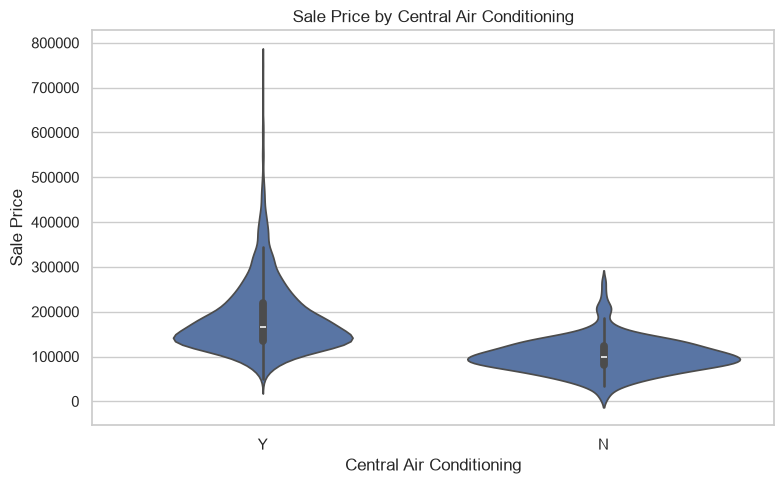

In [13]:
#pret in functie de aer conditionat-violin plot
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=housing,
    x="Central Air",
    y="SalePrice"
)

plt.title("Sale Price by Central Air Conditioning")
plt.xlabel("Central Air Conditioning")
plt.ylabel("Sale Price")
plt.tight_layout()
plt.show()

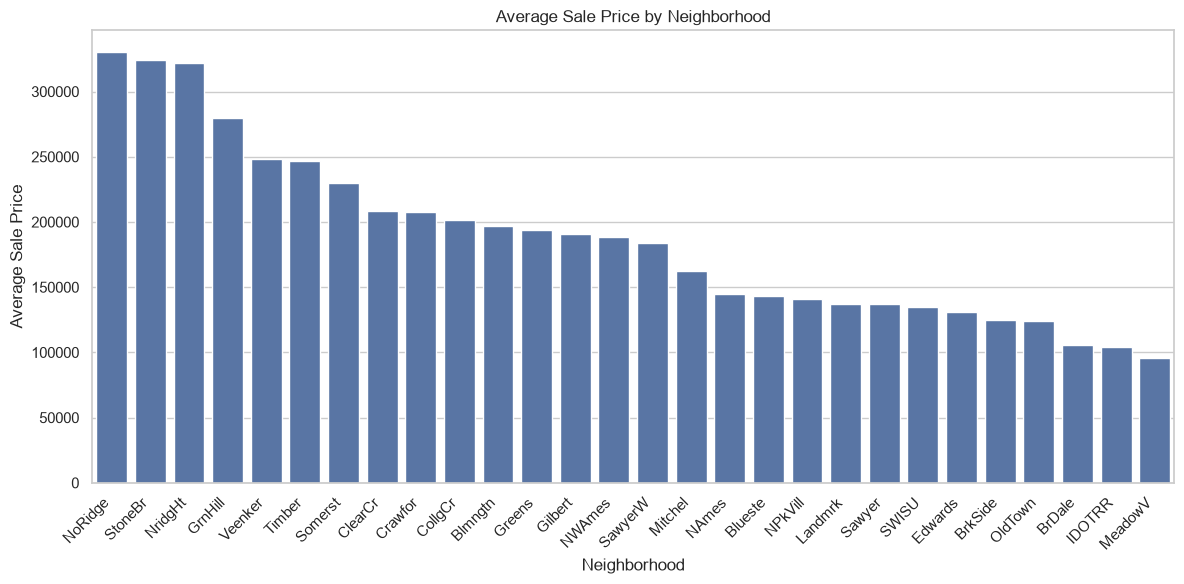

In [14]:
#pretul mediu in functie de cartier
neighborhood_prices = (
    housing.groupby("Neighborhood", observed=True)["SalePrice"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=neighborhood_prices.index,
    y=neighborhood_prices.values
)

plt.title("Average Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average Sale Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#Candidati pentru eliminare

In [15]:
missing = housing.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    "Missing Values": missing,
    "Percentage (%)": (missing / len(housing) * 100).round(2)
})

display(missing_table)

,Missing Values,Percentage (%)
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Cond,159,5.43
Garage Yr Blt,159,5.43


In [16]:
possible_id_columns = [
    col for col in ["Order", "PID"]
    if col in housing.columns
]

print("Possible identifier columns:", possible_id_columns)

Possible identifier columns: ['Order', 'PID']


In [17]:
#corelatia cu pretul
numeric_data = housing.select_dtypes(include="number")

price_correlations = (
    numeric_data.corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values()
)

print("Lowest correlations with SalePrice:")
display(price_correlations.head(10))

print("Highest correlations with SalePrice:")
display(price_correlations.tail(10))

Lowest correlations with SalePrice:


PID               -0.246521
Enclosed Porch    -0.128787
Kitchen AbvGr     -0.119814
Overall Cond      -0.101697
MS SubClass       -0.085092
Low Qual Fin SF   -0.037660
Bsmt Half Bath    -0.035835
Order             -0.031408
Yr Sold           -0.030569
Misc Val          -0.015691
Name: SalePrice, dtype: float64

Highest correlations with SalePrice:


Garage Yr Blt     0.526965
Year Remod/Add    0.532974
Full Bath         0.545604
Year Built        0.558426
1st Flr SF        0.621676
Total Bsmt SF     0.632280
Garage Area       0.640401
Garage Cars       0.647877
Gr Liv Area       0.706780
Overall Qual      0.799262
Name: SalePrice, dtype: float64

In [18]:
#coloane cu o singura valoare
constant_columns = [
    col for col in housing.columns
    if housing[col].nunique(dropna=False) <= 1
]

print("Columns with only one distinct value:")
print(constant_columns)

Columns with only one distinct value:
[]


In [19]:
#crearea unor caracterisitici noi
housing_features = housing.copy()

# Suprafata toata a casei incluzand subsolul
if all(col in housing_features.columns for col in
       ["Gr Liv Area", "Total Bsmt SF"]):
    housing_features["Total House Area"] = (
        housing_features["Gr Liv Area"].fillna(0)
        + housing_features["Total Bsmt SF"].fillna(0)
    )

# Varsta casei la vanzare
if all(col in housing_features.columns for col in
       ["Yr Sold", "Year Built"]):
    housing_features["House Age at Sale"] = (
        housing_features["Yr Sold"] - housing_features["Year Built"]
    )

# Ani de la remodelare in momentul vanzarii
if all(col in housing_features.columns for col in
       ["Yr Sold", "Year Remod/Add"]):
    housing_features["Years Since Remodel"] = (
        housing_features["Yr Sold"] - housing_features["Year Remod/Add"]
    )

new_features = [
    col for col in [
        "Total House Area",
        "House Age at Sale",
        "Years Since Remodel"
    ]
    if col in housing_features.columns
]

display(housing_features[new_features + ["SalePrice"]].head())

,Total House Area,House Age at Sale,Years Since Remodel,SalePrice
0,2736.0,50,50,215000
1,1778.0,49,49,105000
2,2658.0,52,52,172000
3,4220.0,42,42,244000
4,2557.0,13,12,189900


In [ ]:
#posibile date externe:
# Distanța până la școli	
# Distanța până la transportul public	
# Informații despre criminalitate pe cartier	
# Date despre venituri și șomaj pe zonă	
# Date despre impozitele pe proprietate	
# Date istorice despre piața imobiliară

In [20]:
#Bonus: regresie lineara cu scikit-learn
#prezicem SalePrice folosind Gr Liv Area


#pregatirea datelor si antrenarea modelului
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model_data = housing[["Gr Liv Area", "SalePrice"]].dropna()

X = model_data[["Gr Liv Area"]]
y = model_data["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercept:", round(model.intercept_, 2))
print("Coefficient:", round(model.coef_[0], 2))
print("R² score:", round(r2_score(y_test, y_pred), 3))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))

Intercept: 19250.56
Coefficient: 106.73
R² score: 0.523
Mean Absolute Error: 41365.51


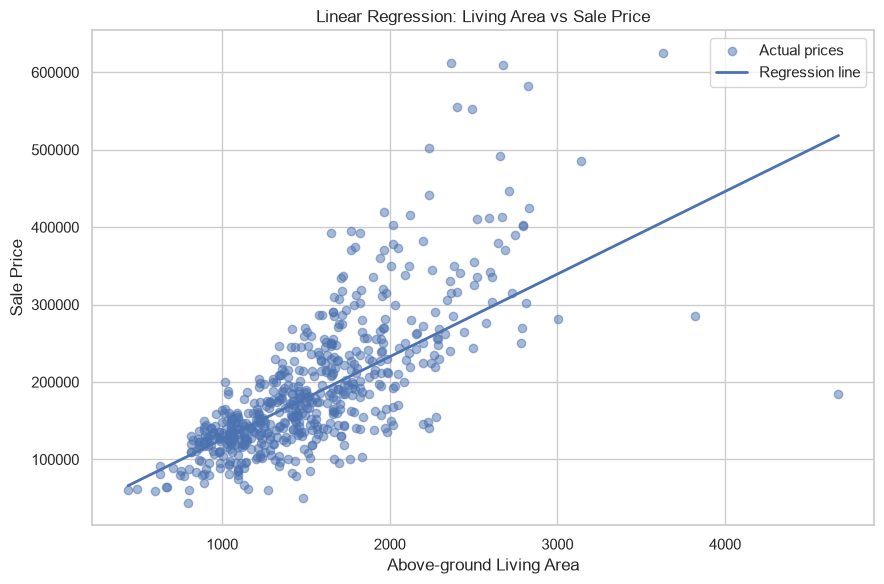

In [21]:
#desenarea dreptei de regresie
plt.figure(figsize=(9, 6))

plt.scatter(
    X_test["Gr Liv Area"],
    y_test,
    alpha=0.5,
    label="Actual prices"
)

x_line = np.linspace(
    X_test["Gr Liv Area"].min(),
    X_test["Gr Liv Area"].max(),
    100
).reshape(-1, 1)

y_line = model.predict(pd.DataFrame(
    x_line, columns=["Gr Liv Area"]
))

plt.plot(x_line.ravel(), y_line, linewidth=2, label="Regression line")

plt.xlabel("Above-ground Living Area")
plt.ylabel("Sale Price")
plt.title("Linear Regression: Living Area vs Sale Price")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
#compararea valorilor reale cu cele prezise
comparison = pd.DataFrame({
    "Actual SalePrice": y_test,
    "Predicted SalePrice": y_pred
})

display(comparison.head(10))

,Actual SalePrice,Predicted SalePrice
1357,161000,197061.331923
2367,116000,129181.589291
2822,196500,203251.622918
2126,123600,124912.423087
1544,126000,117334.653076
2415,174190,160773.419195
2227,200000,128114.297740
410,148500,174648.209356
761,88750,94387.884734
436,409900,288208.030364


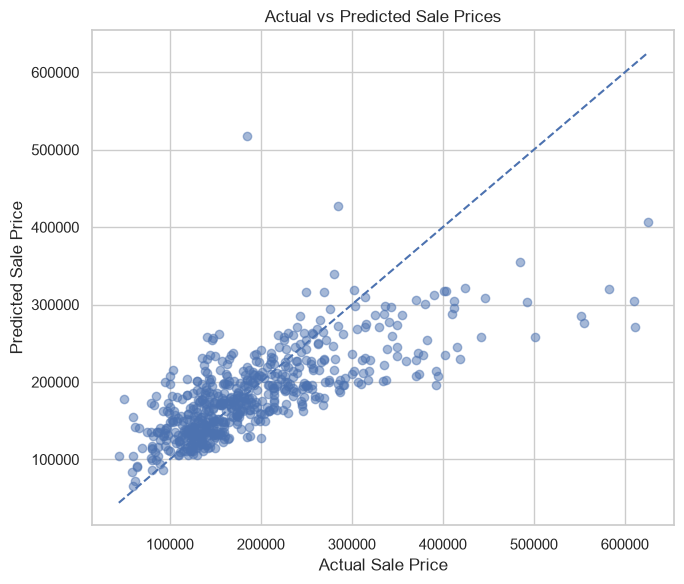

In [23]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted Sale Prices")
plt.tight_layout()
plt.show()